In [1]:
%pip install scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\AMIT\AppData\Local\Programs\Python\Python313\python.exe -m pip install --upgrade pip


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
documents = [
    "football team won the match with excellent goals",
    "the player scored a goal in the football match",
    "cricket team played a great match today",
    "python programming is useful for machine learning",
    "artificial intelligence and machine learning are growing",
    "software developers use python for data science",
    "pizza burger and pasta are popular food items",
    "cooking fresh vegetables makes healthy food",
    "restaurants serve delicious meals and tasty dishes"
]

print("Total documents:", len(documents))

for i, document in enumerate(documents, start=1):
    print(f"Document {i}: {document}")

Total documents: 9
Document 1: football team won the match with excellent goals
Document 2: the player scored a goal in the football match
Document 3: cricket team played a great match today
Document 4: python programming is useful for machine learning
Document 5: artificial intelligence and machine learning are growing
Document 6: software developers use python for data science
Document 7: pizza burger and pasta are popular food items
Document 8: cooking fresh vegetables makes healthy food
Document 9: restaurants serve delicious meals and tasty dishes


In [4]:
vectorizer = TfidfVectorizer(stop_words="english")
tfidf_matrix = vectorizer.fit_transform(documents)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))

TF-IDF matrix shape: (9, 43)
Vocabulary size: 43


In [5]:
n_topics = 3

lsa_model = TruncatedSVD(
    n_components=n_topics,
    n_iter=10,
    random_state=42
)

document_topic_matrix = lsa_model.fit_transform(tfidf_matrix)

print("LSA model trained successfully!")
print("Document-topic matrix shape:", document_topic_matrix.shape)

LSA model trained successfully!
Document-topic matrix shape: (9, 3)


In [6]:
n_topics = 3

lsa_model = TruncatedSVD(
    n_components=n_topics,
    n_iter=10,
    random_state=42
)

document_topic_matrix = lsa_model.fit_transform(tfidf_matrix)

print("LSA model trained successfully!")
print("Document-topic matrix shape:", document_topic_matrix.shape)

LSA model trained successfully!
Document-topic matrix shape: (9, 3)


In [7]:
for index, scores in enumerate(document_topic_matrix):
    dominant_topic = np.argmax(scores) + 1

    print(f"\nDocument {index + 1}: {documents[index]}")
    print("Topic scores:", np.round(scores, 3))
    print("Dominant topic:", dominant_topic)


Document 1: football team won the match with excellent goals
Topic scores: [ 0.777 -0.     0.   ]
Dominant topic: 1

Document 2: the player scored a goal in the football match
Topic scores: [0.661 0.    0.   ]
Dominant topic: 1

Document 3: cricket team played a great match today
Topic scores: [ 0.622 -0.    -0.   ]
Dominant topic: 1

Document 4: python programming is useful for machine learning
Topic scores: [0.    0.826 0.   ]
Dominant topic: 2

Document 5: artificial intelligence and machine learning are growing
Topic scores: [ 0.     0.756 -0.   ]
Dominant topic: 2

Document 6: software developers use python for data science
Topic scores: [0.    0.333 0.   ]
Dominant topic: 2

Document 7: pizza burger and pasta are popular food items
Topic scores: [-0.   -0.    0.75]
Dominant topic: 3

Document 8: cooking fresh vegetables makes healthy food
Topic scores: [ 0.   -0.    0.75]
Dominant topic: 3

Document 9: restaurants serve delicious meals and tasty dishes
Topic scores: [ 0. -0.  0.

In [8]:
import pandas as pd

topic_columns = [
    f"Topic {i + 1}" for i in range(n_topics)
]

topic_df = pd.DataFrame(
    document_topic_matrix,
    columns=topic_columns
)

topic_df.insert(0, "Document", documents)

topic_df.round(3)

,Document,Topic 1,Topic 2,Topic 3
0,football team won the match with excellent goals,0.777,-0.000,0.00
1,the player scored a goal in the football match,0.661,0.000,0.00
2,cricket team played a great match today,0.622,-0.000,-0.00
3,python programming is useful for machine learning,0.000,0.826,0.00
4,artificial intelligence and machine learning a...,0.000,0.756,-0.00
5,software developers use python for data science,0.000,0.333,0.00
6,pizza burger and pasta are popular food items,-0.000,-0.000,0.75
7,cooking fresh vegetables makes healthy food,0.000,-0.000,0.75
8,restaurants serve delicious meals and tasty di...,0.000,-0.000,0.00


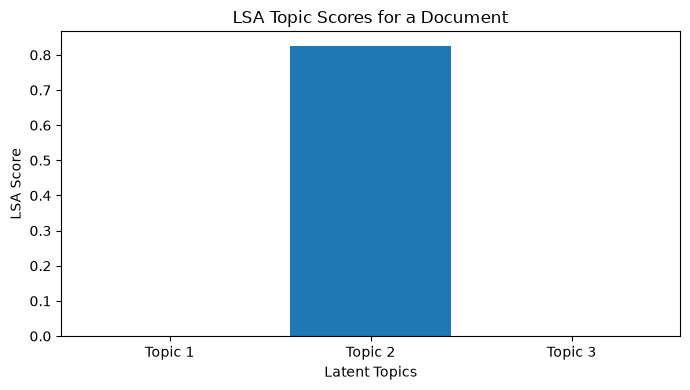

In [9]:
document_index = 3  # Fourth document

plt.figure(figsize=(7, 4))
plt.bar(
    topic_columns,
    document_topic_matrix[document_index]
)

plt.title("LSA Topic Scores for a Document")
plt.xlabel("Latent Topics")
plt.ylabel("LSA Score")
plt.tight_layout()
plt.show()

In [10]:
new_document = [
    "python and machine learning are useful in artificial intelligence"
]

new_tfidf = vectorizer.transform(new_document)

if new_tfidf.nnz == 0:
    print("No known vocabulary words found in the document.")
else:
    new_scores = lsa_model.transform(new_tfidf)[0]
    dominant_topic = np.argmax(new_scores) + 1

    print("New document:", new_document[0])
    print("Topic scores:", np.round(new_scores, 3))
    print("Dominant topic:", dominant_topic)

New document: python and machine learning are useful in artificial intelligence
Topic scores: [0.    0.842 0.   ]
Dominant topic: 2
